# GlyphViz topology animations

Generates the instructional Channels scenes that show how a parent's topology
places **and orients** its children.

Requires `glyphviz_topology_anim.py` in the same folder — this notebook is a
working surface over that module, not a copy of it. Edit the module for
structural changes, then re-run the reload cell below.

**Conventions baked into every scene** (ANTz-compatible, deliberately):

| | |
|---|---|
| parent geometry | **solid**, `color_a = 150`. Wireframe is reserved for the z-variants, so nothing else in a base scene spends that contrast. |
| probe | a small **cone** at scale `(0.28, 0.28, 0.48)` — about a quarter of the unit parent. A cone because half of what a topology does is *orientation*, and a sphere hides it. |
| seating | surface-riding topologies park the probe at `STANDOFF` along the surface-normal axis, so it travels **over** the surface like a satellite instead of being buried to the waist. Altitude `0` puts a child's *origin* on the surface — literally correct, visually wrong. |
| ruler | one dim wireframe at radius 10 (`color_a = 45`), ten times the parent's size, so it can't be misread as a z-variant tell. |
| sweep | three phases of equal length: axis 1 sweeps and returns home, then axis 2, then axis 3. Three tracks, three map rows, one `ch_input_id`. |
| scribe | every single-probe scene grows a fading comet and writes its own path (see §2). |

**The 0.2 render floor matters here.** GlyphViz floors rendered scale at 0.2
per axis. To make the probe smaller than it already is, scale the *parent up*
rather than the probe down — below 0.2 the renderer quietly ignores you and the
glyph draws larger than authored.

In [1]:
import importlib, math, os, sys
sys.path.insert(0, os.getcwd())

import glyphviz_topology_anim as gta
importlib.reload(gta)          # re-run this cell after editing the .py

print("reach:", gta.REACH, "| parent alpha:", gta.PARENT_ALPHA,
      "| probe scale:", gta.PROBE_SCALE, "| standoff:", gta.STANDOFF)
print("wireframe is reserved for topo ids:", sorted(gta.Z_TOPOS))

reach: 10.0 | parent alpha: 150 | probe scale: (0.28, 0.28, 0.48) | standoff: 0.25
wireframe is reserved for topo ids: [9, 10, 11, 12, 13]


## 1. The base scenes

`scene_probe` is the whole grammar: one parent carrying the topology under
test, one cone probe bound to channel 1, three tracks — plus the scribe
effect, which is on by default. Everything else in the series is a variation
on it.

In [2]:
OUT = "topology_animations"
FRAMES_PER_AXIS = 150          # 3 phases -> 450 frames -> 15 s at 30 fps

def emit(folder, scene):
    problems = gta.validate(scene)
    scene.write(os.path.join(OUT, folder))
    frames = max((len(v) for v in scene.tracks.values()), default=0)
    print(f"{folder:34s} {len(scene.nodes):4d} nodes  {len(scene.tracks):4d} tracks  "
          f"{frames:5d} frames  {'OK' if not problems else problems}")

emit("01_grid_probe",   gta.scene_probe(gta.TOPOS[gta.T_NONE],   FRAMES_PER_AXIS))
emit("02_sphere_probe", gta.scene_probe(gta.TOPOS[gta.T_SPHERE], FRAMES_PER_AXIS))

01_grid_probe                       169 nodes   177 tracks    450 frames  OK
02_sphere_probe                     171 nodes   177 tracks    450 frames  OK


### What the coordinates mean

Same three tracks, same sweep, different world. This is the table the
instructional video narrates.

In [3]:
for tid in (gta.T_NONE, gta.T_SPHERE):
    spec = gta.TOPOS[tid]
    print(f"topo {spec.topo}  {spec.title}")
    print(f"    parent geometry {spec.parent_geometry} "
          f"({'wireframe' if spec.topo in gta.Z_TOPOS else 'solid'})")
    for ax in spec.axes:
        print(f"    {ax.field:12s} {ax.name:34s} "
              f"{ax.lo:8.2f} .. {ax.hi:8.2f} {ax.unit:6s} "
              f"home {ax.home:6.2f}{'  (cyclic)' if ax.cyclic else ''}")
    print()

topo 0  Grid / None -- plain Cartesian
    parent geometry 21 (solid)
    translate_x  x                                    -10.00 ..    10.00 units  home   0.00
    translate_y  y                                    -10.00 ..    10.00 units  home   0.00
    translate_z  z                                    -10.00 ..    10.00 units  home   0.00

topo 2  Sphere -- lon / lat / altitude
    parent geometry 3 (solid)
    translate_x  longitude                           -180.00 ..   180.00 deg    home   0.00  (cyclic)
    translate_y  latitude                             -90.00 ..    90.00 deg    home   0.00
    translate_z  altitude                               0.25 ..    10.00 radii  home   0.25



## 2. The scribe effect

Two effects, both derived from the same three probe tracks, so both work on
any topology without extra math:

**Comet** — eight icosahedra parented to the same node, reading the same three
tracks delayed a few frames each and fading out behind the probe. Because they
live in the *parent's topology coordinates*, the tail bends through the
topology exactly as the probe does. On a Sphere it arcs; on a Torus it wraps
the tube; on a Pin it stacks.

**Chalk line** — a transparent Plot-topology parent holding 150 beads at the
probe's *Cartesian world* positions, computed with the topology's own offset
function. Each bead's alpha is a step function that flips on as the probe
arrives and stays on, so the curve draws itself. Plot draws its polyline
through children in row order, which is why the beads are emitted in path
order.

The second one is the reason to bother: the probe moves in the topology's
coordinates while the line accumulates in world space, so the mapping between
the two is on screen simultaneously rather than narrated. Turn it off with
`scribe=False` if a lesson needs the bare mechanism.

In [4]:
plain = gta.scene_probe(gta.TOPOS[gta.T_SPHERE], FRAMES_PER_AXIS, scribe=False)
fancy = gta.scene_probe(gta.TOPOS[gta.T_SPHERE], FRAMES_PER_AXIS, scribe=True)
print(f"scribe=False -> {len(plain.nodes):4d} nodes, {len(plain.tracks):4d} tracks")
print(f"scribe=True  -> {len(fancy.nodes):4d} nodes, {len(fancy.tracks):4d} tracks")
print("\nchannel map, first 6 rows:")
for row in fancy.chmap[:6]:
    print("   ", row)

scribe=False ->   12 nodes,    3 tracks
scribe=True  ->  171 nodes,  177 tracks

channel map, first 6 rows:
    (1, 1, 'translate_x')
    (1, 2, 'translate_y')
    (1, 3, 'translate_z')
    (2, 4, 'translate_x')
    (2, 5, 'translate_y')
    (2, 6, 'translate_z')


## 3. Preview the sweep before opening GlyphViz

The probe's path in *world* Cartesian space — the same curve the chalk line
will draw — computed with the same offset functions the engine uses. Worth a
look whenever you retune a sweep; a lot faster than a round trip through the
app.

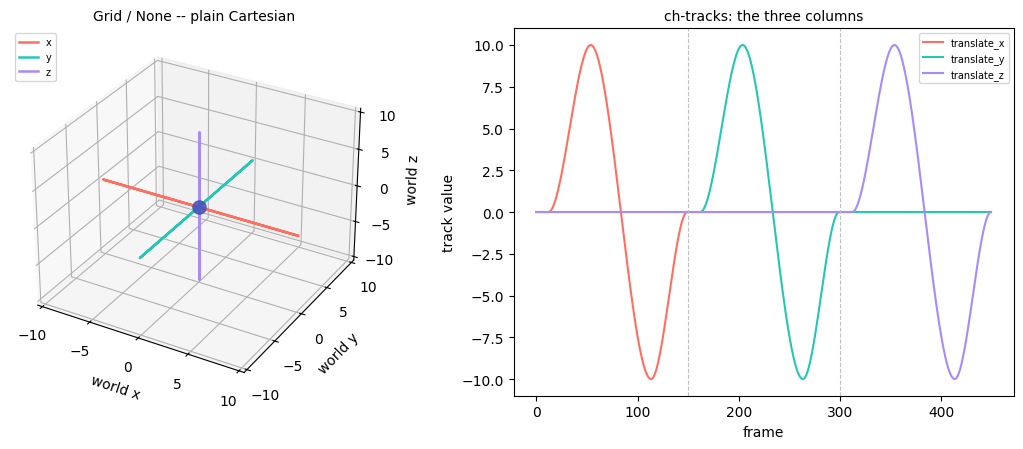

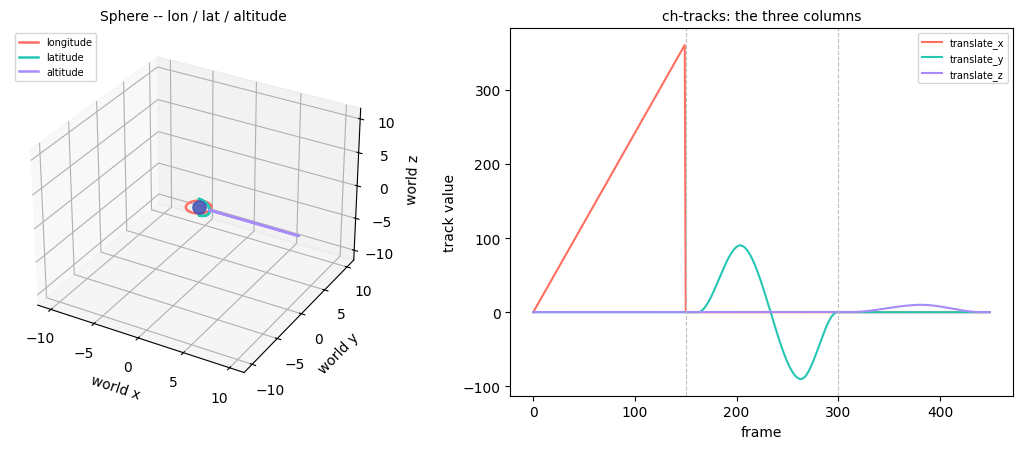

In [5]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

def probe_path(spec, frames_per_axis=FRAMES_PER_AXIS):
    tx, ty, tz = gta.probe_tracks(spec, frames_per_axis)
    pts = [spec.offset(tx[i], ty[i], tz[i], ratio=spec.ratio, facet=spec.facet or 1)
           for i in range(len(tx))]
    return tx, ty, tz, pts

def preview(spec, frames_per_axis=FRAMES_PER_AXIS, lim=None):
    tx, ty, tz, pts = probe_path(spec, frames_per_axis)
    n = frames_per_axis
    fig = plt.figure(figsize=(11, 4.6))

    ax3 = fig.add_subplot(1, 2, 1, projection="3d")
    for phase, col in enumerate(("#FF6F61", "#26C6B5", "#A78BFA")):
        seg = pts[phase * n:(phase + 1) * n]
        ax3.plot([p[0] for p in seg], [p[1] for p in seg], [p[2] for p in seg],
                 color=col, lw=1.8, label=spec.axes[phase].name)
    ax3.scatter([0], [0], [0], color="#3F51B5", s=90, alpha=0.85)
    lim = lim or max(max(abs(c) for c in p) for p in pts) * 1.05
    ax3.set_xlim(-lim, lim); ax3.set_ylim(-lim, lim); ax3.set_zlim(-lim, lim)
    ax3.set_xlabel("world x"); ax3.set_ylabel("world y"); ax3.set_zlabel("world z")
    ax3.set_title(spec.title, fontsize=10)
    ax3.legend(fontsize=7, loc="upper left")

    ax2 = fig.add_subplot(1, 2, 2)
    for lane, ax_spec, col in zip((tx, ty, tz), spec.axes,
                                  ("#FF6F61", "#26C6B5", "#A78BFA")):
        ax2.plot(lane, color=col, lw=1.5, label=ax_spec.field)
    for b in (n, 2 * n):
        ax2.axvline(b, color="0.75", lw=0.8, ls="--")
    ax2.set_xlabel("frame"); ax2.set_ylabel("track value")
    ax2.set_title("ch-tracks: the three columns", fontsize=10)
    ax2.legend(fontsize=7)
    plt.tight_layout(); plt.show()

preview(gta.TOPOS[gta.T_NONE])
preview(gta.TOPOS[gta.T_SPHERE])

Note the sphere's third phase: altitude runs to 10 while the parent has radius
1, so the probe leaves the planet entirely. That is the honest shape of the
coordinate system, and it is exactly what makes the Rosetta scene land.

## 4. The multi-child variations

These stay **clean — no scribe**. With three or twelve probes already in
flight, a comet and a chalk line each would read as clutter rather than
clarity.

- **`03_grid_axis_triad`** — three probes, three channels, **one track
  column**. Several channels may read the same track, so a single sweep drives
  motion along three different axes. The probes' common corner traces the
  diagonal.
- **`04_sphere_meridian_comb`** — twelve children, **one channel**. It
  overwrites only latitude, altitude and colour, so each child keeps its own
  longitude from the CSV. The compression pattern, at a size where the trick
  is still visible.
- **`05_rosetta_grid_vs_sphere`** — two parents, **byte-identical numbers**,
  one channel. ±10 units against ±10 degrees. Angles wrap; distances don't.
  Deliberately no standoff on the sphere probe: the whole point is that both
  probes receive the same values.

In [6]:
emit("03_grid_axis_triad",        gta.scene_axis_triad())
emit("04_sphere_meridian_comb",   gta.scene_meridian_comb())
emit("05_rosetta_grid_vs_sphere", gta.scene_rosetta(FRAMES_PER_AXIS))

03_grid_axis_triad                   12 nodes     1 tracks    210 frames  OK
04_sphere_meridian_comb              15 nodes     5 tracks    260 frames  OK
05_rosetta_grid_vs_sphere             7 nodes     3 tracks    450 frames  OK


## 5. The rest of the first eight

Cube, Torus, Cylinder, Pin, Rod and Point already have full sweep
specifications in `gta.TOPOS`, including their seating standoffs and their
solid/wire geometry pair — so each is one call, scribe included. Adding a
z-variant later means one table entry: `parent_geometry` picks the wireframe
automatically once the topo id is in `Z_TOPOS`.

In [7]:
for tid in (gta.T_CUBE, gta.T_TORUS, gta.T_CYLINDER,
            gta.T_PIN, gta.T_ROD, gta.T_POINT):
    spec = gta.TOPOS[tid]
    emit(f"next_up/topo{tid:02d}_{spec.key}_probe",
         gta.scene_probe(spec, FRAMES_PER_AXIS))

next_up/topo01_cube_probe           169 nodes   177 tracks    450 frames  OK
next_up/topo03_torus_probe          173 nodes   177 tracks    450 frames  OK
next_up/topo04_cylinder_probe       171 nodes   177 tracks    450 frames  OK


next_up/topo05_pin_probe            169 nodes   177 tracks    450 frames  OK
next_up/topo06_rod_probe            171 nodes   177 tracks    450 frames  OK


next_up/topo07_point_probe          171 nodes   177 tracks    450 frames  OK


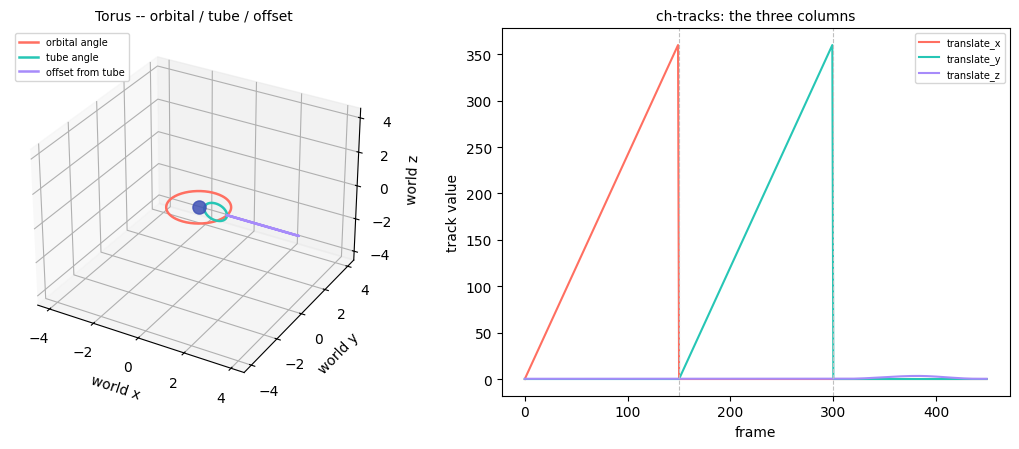

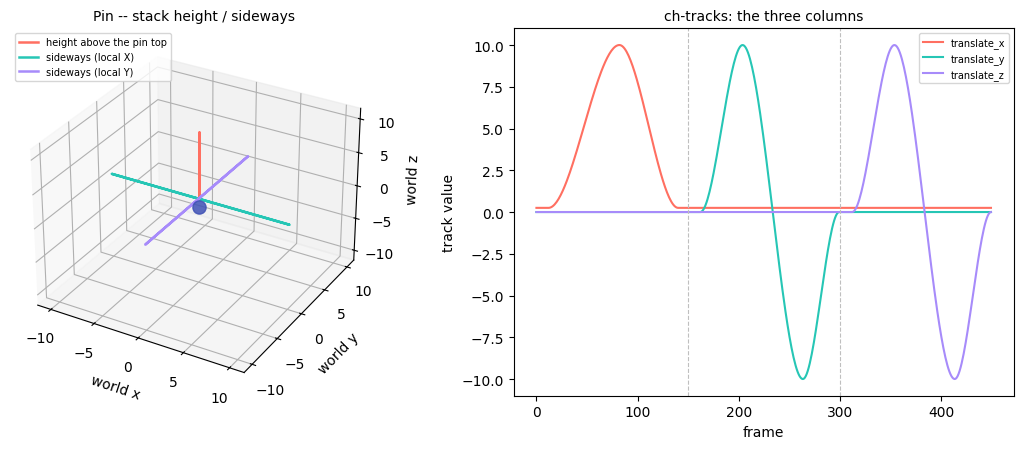

In [8]:
# Preview any of them the same way.
preview(gta.TOPOS[gta.T_TORUS])
preview(gta.TOPOS[gta.T_PIN])

## 6. Wiring in the lesson video

`add_screen()` drops an upright plate (geometry 21, topo 15 *Video*) into a
scene on `texture_id` 1, standing vertically via `rotate_x = 90`.

That single non-zero rotation is what makes the file write a `rotation_mode`
column. A node CSV *without* that column loads in ANTz Heading/Tilt/Roll
(Z-X-Z) mode, so a hand-posed rotation would be misread; with any rotation
present the writer emits an explicit `rotation_mode = 0`, meaning Euler XYZ —
each field spinning its own axis. Scenes with no rotations stay minimal and
omit the column entirely.

Create a `media/` folder beside the node CSV and put the video in it —
`texture_id` is a 1-based index into that folder, sorted images first, then
videos.

For audio-locked playback instead of the FPS timer, put a one-line
`<anything>_gv_audio.txt` next to the node CSV containing a relative path to an
audio file. Frame advance then follows real audio position, so render
slowdowns cost smoothness rather than sync.

In [9]:
scene = gta.scene_probe(gta.TOPOS[gta.T_SPHERE], FRAMES_PER_AXIS, screen=True)
emit("06_sphere_probe_with_screen", scene)

media = os.path.join(OUT, "06_sphere_probe_with_screen", "media")
os.makedirs(media, exist_ok=True)
with open(os.path.join(media, "PUT_THE_LESSON_VIDEO_HERE.txt"), "w",
          encoding="utf-8") as fh:
    fh.write("texture_id is a 1-based index into this folder, images first "
             "then videos.\nThe screen node uses texture_id 1, so the first "
             "file here is what plays.\n")

screen = [n for n in scene.nodes if n["texture_id"]][0]
print("\nscreen node:", {k: screen[k] for k in
      ("translate_y", "translate_z", "rotate_x", "geometry", "topo", "texture_id")})

06_sphere_probe_with_screen         172 nodes   177 tracks    450 frames  OK

screen node: {'translate_y': 19.0, 'translate_z': 4.62, 'rotate_x': 90.0, 'geometry': 21, 'topo': 15, 'texture_id': 1}


## 7. Housekeeping

**One scene per folder is mandatory.** GlyphViz auto-loads Channels only when
it finds exactly one `ch-map` and one `ch-tracks` file in the node CSV's
folder; two candidates disable Channels entirely, silently.

Playback: `Space` play/pause, `Shift+Space` stop (resets to frame 0 and
restores the CSV values), `T` toggles labels, `C` cycles stored cameras.

Two things worth a skeptical first look:

1. The scribe's Plot parent uses `color_a = 0` rather than `hide = 1`, on the
   guess that hiding a parent might suppress its overlay. If `hide` works, it
   is cleaner.
2. Alpha-0 chalk beads may leave a faint ghost of the whole path depending on
   blend mode. If so, set the World row's `render_mode` to 1 (Additive).

In [10]:
import glob
for f in sorted(glob.glob(os.path.join(OUT, "**", "*_gv_node.csv"), recursive=True)):
    d = os.path.dirname(f)
    maps = glob.glob(os.path.join(d, "*ch-map*.csv"))
    trks = glob.glob(os.path.join(d, "*ch-track*.csv"))
    flag = "ok" if len(maps) == 1 and len(trks) == 1 else "!! Channels will not auto-load"
    print(f"{os.path.relpath(d, OUT):34s} maps={len(maps)} tracks={len(trks)}  {flag}")

01_grid_probe                      maps=1 tracks=1  ok
02_sphere_probe                    maps=1 tracks=1  ok
03_grid_axis_triad                 maps=1 tracks=1  ok
04_sphere_meridian_comb            maps=1 tracks=1  ok
05_rosetta_grid_vs_sphere          maps=1 tracks=1  ok
06_sphere_probe_with_screen        maps=1 tracks=1  ok
next_up/topo01_cube_probe          maps=1 tracks=1  ok
next_up/topo03_torus_probe         maps=1 tracks=1  ok
next_up/topo04_cylinder_probe      maps=1 tracks=1  ok
next_up/topo05_pin_probe           maps=1 tracks=1  ok
next_up/topo06_rod_probe           maps=1 tracks=1  ok
next_up/topo07_point_probe         maps=1 tracks=1  ok
